# Matched controls and structural ablation

Test time supervision, prefix anchoring and reciprocal-cycle drift on the same
15 site-held-out splits. Transformer controls share the hidden width and epoch
ceiling, with different parameter counts. Ratios compare the recorded model fits.

In [1]:
from pathlib import Path
import sys
import os
from datetime import datetime, timezone
os.environ.setdefault("LIQ_FINAL_DEVICE", os.environ.get("LIQ_DEVICE", "cpu"))
os.environ.setdefault("LIQ_DEVICE", os.environ["LIQ_FINAL_DEVICE"])
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "pyproject.toml").is_file() and (p / "src/dpi_evt").is_dir())
for directory in (ROOT / "src", ROOT / "external_validation", ROOT / "scripts"):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11,
                     "font.family": "DejaVu Sans", "axes.grid": True, "grid.alpha": .2})
COLORS = {"DPI-EVT":"#246aac", "DPI-EVT +A":"#1b9e8a", "EVT-NeuralSSM":"#69788a",
          "Transformer +cummax":"#c17a24", "Transformer matched +A/crossing loss":"#8658a6",
          "GP prefix (linear + SE)":"#8469a5", "Threshold-projected Transformer/GBM":"#777777",
          "Time-warped Transformer/GBM":"#b685b3", "GBM horizon mixture":"#a66c20", "Cox PH":"#555555"}
TABLES = ROOT / "results/tables"
print("Executed:", datetime.now(timezone.utc).isoformat(timespec="seconds"))
print("Inputs: included aggregate tables and public external extracts")

Executed: 2026-11-06T14:06:58+00:00
Inputs: included aggregate tables and public external extracts


## Fixed controls and primary errors

,curve_rmse,onset_logmae,noncrossing
model,,,
DPI-EVT +A,0.1069,0.5863,0.1224
DPI-EVT +A/no reciprocal drift,0.1471,0.6772,0.0918
Transformer matched +P/head loss,0.1095,0.7948,0.0762
Transformer matched +P/crossing loss,0.1064,0.6330,0.0776
Transformer matched +A/crossing loss,0.1017,0.6234,0.0850


,reference,comparator,metric,ratio,ratio_lo,ratio_hi
12,DPI-EVT +A,Transformer matched +A/crossing loss,onset_logmae,0.9405,0.6778,1.3375
13,DPI-EVT +A,Transformer matched +A/crossing loss,curve_rmse,1.0510,0.9575,1.1413
16,Transformer matched +P/crossing loss,Transformer matched +P/head loss,onset_logmae,0.7964,0.5113,1.2824
17,Transformer matched +P/crossing loss,Transformer matched +P/head loss,curve_rmse,0.9712,0.8937,1.0806
18,DPI-EVT +A,DPI-EVT +A/no reciprocal drift,onset_logmae,0.8658,0.6921,1.1342
19,DPI-EVT +A,DPI-EVT +A/no reciprocal drift,curve_rmse,0.7268,0.6207,0.8525


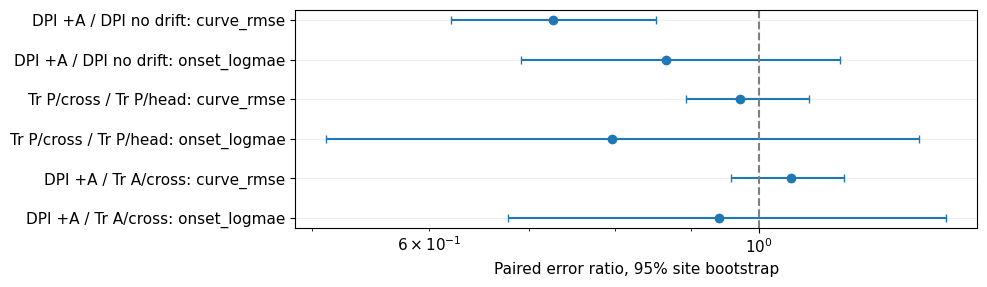

In [2]:
joint=pd.read_csv(TABLES/"joint_metrics.csv")
internal=joint[joint.source.eq("internal")].set_index("model")
names=["DPI-EVT +A","DPI-EVT +A/no reciprocal drift","Transformer matched +P/head loss",
       "Transformer matched +P/crossing loss","Transformer matched +A/crossing loss"]
display(internal.loc[names,["curve_rmse","onset_logmae","noncrossing"]].round(4))
paired=pd.read_csv(TABLES/"internal_paired_bootstrap.csv")
focus=paired[paired.comparator.isin(names) & paired.reference.isin(names)]
display(focus[["reference","comparator","metric","ratio","ratio_lo","ratio_hi"]].round(4))
fig,ax=plt.subplots(figsize=(10,max(3,.5*len(focus))))
y=np.arange(len(focus))
ax.errorbar(focus.ratio,y,xerr=[focus.ratio-focus.ratio_lo,focus.ratio_hi-focus.ratio],fmt="o",capsize=3)
ax.axvline(1,color="grey",linestyle="--")
short={"DPI-EVT +A":"DPI +A","DPI-EVT +A/no reciprocal drift":"DPI no drift",
       "Transformer matched +A/crossing loss":"Tr A/cross",
       "Transformer matched +P/crossing loss":"Tr P/cross",
       "Transformer matched +P/head loss":"Tr P/head"}
ax.set_yticks(y,[f"{short[a]} / {short[b]}: {m}" for a,b,m in zip(focus.reference,focus.comparator,focus.metric)])
ax.set(xlabel="Paired error ratio, 95% site bootstrap",xscale="log")
fig.tight_layout();plt.show()

## Controlled structural result

In [3]:
full=internal.loc["DPI-EVT +A","curve_rmse"]
ablated=internal.loc["DPI-EVT +A/no reciprocal drift","curve_rmse"]
print("Continuation RMSE reduction retaining reciprocal drift:",f"{1-full/ablated:.1%}")
from dpi_evt.models.controls import CrossingTransformer,DPINoReciprocalDrift
print("Control implementations:",CrossingTransformer.__name__,DPINoReciprocalDrift.__name__)

Continuation RMSE reduction retaining reciprocal drift: 27.3%


Control implementations: CrossingTransformer DPINoReciprocalDrift


## Refit the controls with authorized data

In [4]:
RUN_CONTROLS = False
if RUN_CONTROLS:
    from train_controls import run_controls
    from analyze_controls import analyze
    print(run_controls(workers=3))
    print(analyze())
else:
    print("Control summaries loaded. The drift ablation removes the two reciprocal-cycle pressure-rate terms.")

Control summaries loaded. The drift ablation removes the two reciprocal-cycle pressure-rate terms.
